# Linear Regression

## Create dataset

In [2]:
import numpy as np

np.random.seed(42)  # to make this code example reproducible
m = 100  # number of instances
X = 2 * np.random.rand(m, 1)  # this a function creates a shape with 1 column and m rows (m=100, so 100 rows), thus creating a column vector because it has only one column
y = 4 + 3 * X + np.random.randn(m, 1)  # Y here is scaled by 3 and is shifted by 4, and since it has only one column, it is called column vector
print(X[0]) #first value of X
print(y[0]) #first value of y
print(X[99]) #last value of X
print(y[99]) #last value of y

[0.74908024]
[6.33428778]
[0.21578285]
[5.47453181]


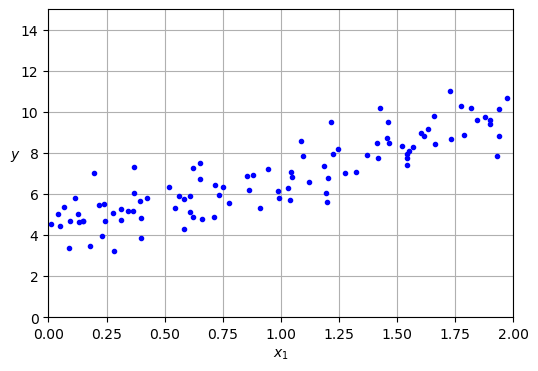

In [3]:
# extra code – generates and saves Figure 4–1

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.") #creating a dotted blue points on the x and y axis
plt.xlabel("$x_1$") #the default rotation for xlabel is 0
plt.ylabel("$y$", rotation=0) #while the default rotation for ylabel is 90, so the rotation will need to be adjusted to 0
plt.axis([0, 2, 0, 15])
plt.grid()
#save_fig("generated_data_plot")
plt.show()

## Linear Regression

In [3]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression() #creating a class
lin_reg.fit(X, y) #fitting and training the model
lin_reg.intercept_, lin_reg.coef_ #printing out the intercept bias term value, and the coeffient slope value

(array([4.21509616]), array([[2.77011339]]))

In [4]:
X_new = np.array([[0], [2]]) #creating an array and assigning it to the variable X_new
print(X_new.shape)

(2, 1)


In [5]:
y_predict=lin_reg.predict(X_new) #model makes predictions based on the data in the variable X_new

In [6]:
y_predict

array([[4.21509616],
       [9.75532293]])

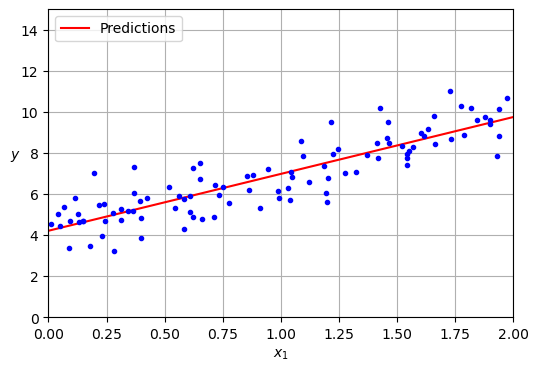

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))  # extra code – not needed, just formatting
plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, y, "b.")

# extra code – beautifies and saves Figure 4–2
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.legend(loc="upper left") #creating and adjusting the location of the label box
#save_fig("linear_model_predictions_plot")

plt.show()

# Gradient Descent
## Batch Gradient Descent

### Convergence 
### Divergence 

In [8]:
from sklearn.preprocessing import add_dummy_feature

eta = 0.01  # learning rate is slower now from 0.1 decreased to 0.01 to improve the model
n_epochs = 1000 #storing the value 1000 in the variable n_epochs
#X = 2 * np.random.rand(m, 1), that's just how X was initialized initially
X_b = add_dummy_feature(X)  # add x0 = 1 to each instance
X_new_b = add_dummy_feature(X_new)
m = len(X_b)  # number of instances
#print(X)
#print(len(X))        output: 100
#print(X_b)
# print(len(X_b))      output: 100
#print(X_new_b)
# print(len(X_new_b))   output: 2 
#print(m)     output: 100, which makes sense because the value of the length of X_b was previously stored in the variable m 



tolerance = 1e-5
Lhistory=[]



np.random.seed()
theta = np.random.randn(2, 1)  # randomly initialized model parameters

for epoch in range(n_epochs):
    #print(epoch, gradients, theta)
    #print(theta[0])
    #print(theta[1])
    #print(theta)
    #print(X_b.T) #the output is the transpose of X_b
    #print(X_b @ theta)
    predictions_y = X_b @ theta
    mistakes = X_b @ theta - y
    Lhistory.append(mistakes)
    gradients = 2 / m * X_b.T @ (predictions_y - y)
    theta = theta - (eta * gradients)
    # extra code – to detect convergence (very little to no improvement)
    if epoch > 0:
        error = abs(Lhistory[-1] - Lhistory[-2])
        if np.any(error < tolerance): # if the absolute error is less than the tolerance (the tolerance which is equal to 0.00001), then stop the training due to convergence, becuase the model has learned enough and there is no to very little improvement gained from continuing the training
            print(f"Converged at epoch {epoch}" + f" with error {error}")
            break
    # extra code – to detecting divergence due to high learning rate
    if epoch > 130:
        if len(Lhistory) > 1 and np.any(Lhistory[-1] > Lhistory[-2] * 1.7): # if the last error is 70% larger than the previous error, then assume divergence and stop the training due to high learning rate
            print(f"The learning rate is too high. The last epoch was {epoch} while the learning rate equal to {eta}")
            break

Converged at epoch 125 with error [[2.54648902e-03]
 [8.05893028e-05]
 [1.01666471e-03]
 [1.58731135e-03]
 [3.48171323e-03]
 [3.48181646e-03]
 [3.90085377e-03]
 [4.42394171e-04]
 [1.57679795e-03]
 [1.11904292e-03]
 [4.06134181e-03]
 [1.56344163e-06]
 [5.86766207e-04]
 [3.24067392e-03]
 [3.37126779e-03]
 [3.36450769e-03]
 [2.84734858e-03]
 [1.90359600e-03]
 [2.30080858e-03]
 [2.90304182e-03]
 [1.53084215e-03]
 [3.55243568e-03]
 [2.89912364e-03]
 [2.58149025e-03]
 [2.19755900e-03]
 [7.89057274e-04]
 [3.29487876e-03]
 [1.94862783e-03]
 [1.61403394e-03]
 [3.95064132e-03]
 [1.54927964e-03]
 [3.41963293e-03]
 [3.87103233e-03]
 [8.84160355e-05]
 [1.67446900e-05]
 [6.89674809e-04]
 [2.84575853e-03]
 [3.73142362e-03]
 [1.22107099e-03]
 [2.26568238e-03]
 [3.62714195e-03]
 [2.03018989e-03]
 [4.00226358e-03]
 [2.57746175e-04]
 [3.04191713e-03]
 [1.31398823e-03]
 [2.81538360e-03]
 [1.92366137e-03]
 [1.80963832e-03]
 [3.35830224e-03]
 [1.71552221e-07]
 [8.32039712e-04]
 [1.28588616e-04]
 [3.19773272

In [9]:
print(gradients)

[[-0.41066956]
 [ 0.21650861]]


In [10]:
Lhistory[-1]

array([[-0.41396259],
       [ 0.69803031],
       [ 0.03169009],
       [ 1.94302659],
       [-0.38256515],
       [-0.95938   ],
       [-2.20352225],
       [ 0.81078111],
       [ 0.76704633],
       [ 0.59506869],
       [-1.68827654],
       [ 0.09445687],
       [ 0.77976928],
       [-1.04454469],
       [-0.66680045],
       [-1.53637778],
       [ 0.28656725],
       [ 0.19000849],
       [ 0.13751872],
       [ 1.03163352],
       [-0.32403859],
       [-0.88411236],
       [-0.43584141],
       [-0.10263243],
       [ 1.19117705],
       [ 0.61110175],
       [-0.20452015],
       [ 0.65136665],
       [ 0.1088765 ],
       [-1.14433607],
       [-1.91953204],
       [-0.75853897],
       [-0.97439944],
       [ 0.47116476],
       [ 2.33658945],
       [ 0.2462276 ],
       [-0.47524796],
       [-3.13899162],
       [ 0.25563647],
       [-0.54579594],
       [-0.61033816],
       [ 0.99375629],
       [-1.89830515],
       [-0.40506345],
       [-1.26379701],
       [ 0

In [11]:
Lhistory[-2]

array([[-0.41650908],
       [ 0.69794972],
       [ 0.03067342],
       [ 1.94143928],
       [-0.38604686],
       [-0.96286182],
       [-2.2074231 ],
       [ 0.81033872],
       [ 0.76546953],
       [ 0.59394965],
       [-1.69233789],
       [ 0.09445844],
       [ 0.77918252],
       [-1.04778536],
       [-0.67017172],
       [-1.53974229],
       [ 0.2837199 ],
       [ 0.1881049 ],
       [ 0.13521791],
       [ 1.02873048],
       [-0.32556943],
       [-0.88766479],
       [-0.43874053],
       [-0.10521392],
       [ 1.18897949],
       [ 0.61031269],
       [-0.20781503],
       [ 0.64941802],
       [ 0.10726246],
       [-1.14828671],
       [-1.92108132],
       [-0.76195861],
       [-0.97827047],
       [ 0.47107634],
       [ 2.33657271],
       [ 0.24553792],
       [-0.47809372],
       [-3.14272305],
       [ 0.2544154 ],
       [-0.54806162],
       [-0.6139653 ],
       [ 0.9917261 ],
       [-1.90230741],
       [-0.40532119],
       [-1.26683892],
       [ 0

The trained model parameters:

In [12]:
theta #it only prints the output of the last variable when written like this, but if you tried adding other variable in the same code box, it will only print the last one

array([[3.20529727],
       [3.62779934]])

In [13]:
print(theta[0])
print(theta[1])
print(theta)

[3.20529727]
[3.62779934]
[[3.20529727]
 [3.62779934]]


In [14]:
len(Lhistory)

126

In [15]:
m = len(X_b)
print(m)

100


In [16]:
len(y)

100

In [17]:
len(X)

100

In [18]:
len(theta)

2

In [19]:
y

array([[ 6.33428778],
       [ 9.40527849],
       [ 8.48372443],
       [ 5.60438199],
       [ 4.71643995],
       [ 5.29307969],
       [ 5.82639572],
       [ 8.67878666],
       [ 6.79819647],
       [ 7.74667842],
       [ 5.03890908],
       [10.14821022],
       [ 8.46489564],
       [ 5.7873021 ],
       [ 5.18802735],
       [ 6.06907205],
       [ 5.12340036],
       [ 6.82087644],
       [ 6.19956196],
       [ 4.28385989],
       [ 7.96723765],
       [ 5.09801844],
       [ 5.75798135],
       [ 5.96358393],
       [ 5.32104916],
       [ 8.29041045],
       [ 4.85532818],
       [ 6.28312936],
       [ 7.3932017 ],
       [ 4.68275333],
       [ 9.53145501],
       [ 5.19772255],
       [ 4.64785995],
       [ 9.61886731],
       [ 7.87502098],
       [ 8.82387021],
       [ 5.88791282],
       [ 7.0492748 ],
       [ 7.91303719],
       [ 6.9424623 ],
       [ 4.69751764],
       [ 5.80238342],
       [ 5.34915394],
       [10.20785545],
       [ 6.34371184],
       [ 7

In [20]:
X

array([[0.74908024],
       [1.90142861],
       [1.46398788],
       [1.19731697],
       [0.31203728],
       [0.31198904],
       [0.11616722],
       [1.73235229],
       [1.20223002],
       [1.41614516],
       [0.04116899],
       [1.9398197 ],
       [1.66488528],
       [0.42467822],
       [0.36364993],
       [0.36680902],
       [0.60848449],
       [1.04951286],
       [0.86389004],
       [0.58245828],
       [1.22370579],
       [0.27898772],
       [0.5842893 ],
       [0.73272369],
       [0.91213997],
       [1.57035192],
       [0.39934756],
       [1.02846888],
       [1.18482914],
       [0.09290083],
       [1.2150897 ],
       [0.34104825],
       [0.13010319],
       [1.89777107],
       [1.93126407],
       [1.6167947 ],
       [0.60922754],
       [0.19534423],
       [1.36846605],
       [0.88030499],
       [0.24407647],
       [0.99035382],
       [0.06877704],
       [1.8186408 ],
       [0.51755996],
       [1.32504457],
       [0.62342215],
       [1.040

In [21]:
print(len(X))

100


In [22]:
len(Lhistory)

126

In [23]:
## self study example apart from the notebook for training the model
## Mean Squared Error Cost Function
# def computeCost (X, y, theta):
#     m = len(y)
#     predictions = X @ theta
#     errors = predictions - y
#     return (1/(2*m)) * np.sum(errors**2)

In [24]:
## self study example apart from the notebook for training the model
# import numpy as np
# X = np.array([[1, 2], [1, 3], [1, 4]])    # the array has 3 samples, 2 features that are stored in the variable X
# y = np.array([3, 4, 5])       # y represent the target values
# theta = np.array([0.5, 1])              # the parameters of theta are the 0.5 which represents the intercept value, and the 1 which represents the coffient slope value

# print(computeCost(X, y, theta))

In [25]:
(1/(2*m))

0.005

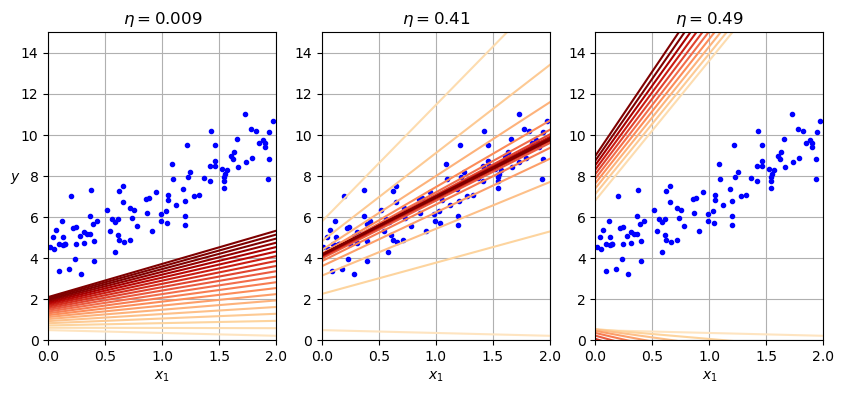

In [26]:
# extra code – generates and saves Figure 4–8

import matplotlib as mpl

def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_epochs = 1000
    n_shown = 20
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

plt.figure(figsize=(10, 4))
plt.subplot(131)
plot_gradient_descent(theta, eta=0.009) #an example of a very low learning rate that will take a long time until it reaches the solution
plt.ylabel("$y$", rotation=0)
plt.subplot(132)
theta_path_bgd = plot_gradient_descent(theta, eta=0.41) #an example of an optimal learning rate
#plt.gca().axes.yaxis.set_ticklabels([])
plt.subplot(133)
#plt.gca().axes.yaxis.set_ticklabels([])
plot_gradient_descent(theta, eta=0.49) #an exxample of a very high learning rate that is getting further away from the solution
#save_fig("gradient_descent_plot")
plt.show()

## Stochastic Gradient Descent

In [27]:
theta_path_sgd = [] #initializing an empty list, and setting it to the variable theta_path_sgd
 # extra code – we need to store the path of theta in the
 #              parameter space to plot the next figure

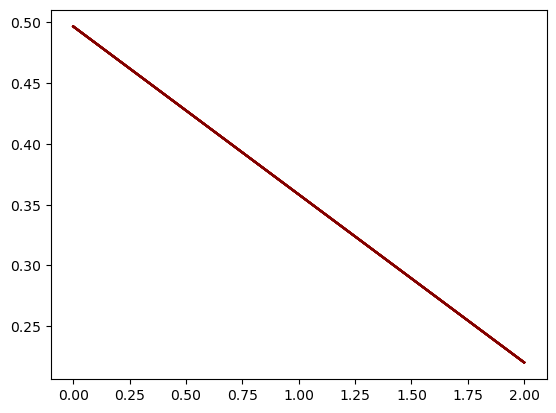

In [28]:
t0, t1 = 5, 50 
def learning_schedule(t):
    return t0 / (t + t1)
n_shown = 20
for epoch in range(n_epochs):
    for iteration in range(m):

        # extra code – these 4 lines are used to generate the figure
        if epoch == 0 and iteration < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(iteration / n_shown + 0.15))
            plt.plot(X_new, y_predict, color=color)

        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)  # for SGD, do not divide by m
        eta = learning_schedule(epoch * m + iteration)

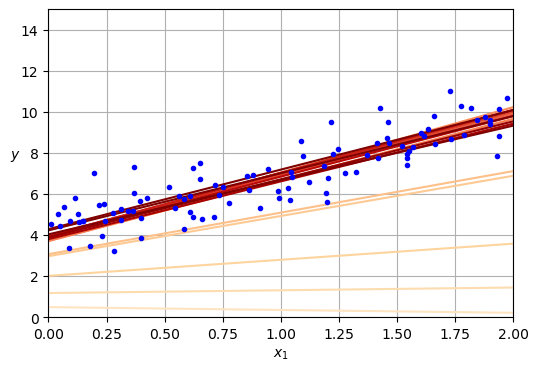

In [29]:
n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

n_shown = 20  # extra code – just needed to generate the figure below
plt.figure(figsize=(6, 4))  # extra code – not needed, just formatting

for epoch in range(n_epochs):
    for iteration in range(m):

        # extra code – these 4 lines are used to generate the figure
        if epoch == 0 and iteration < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(iteration / n_shown + 0.15))
            plt.plot(X_new, y_predict, color=color)

        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)  # for SGD, do not divide by m
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)  # extra code – to generate the figure

# extra code – this section beautifies and saves Figure 4–10
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
#save_fig("sgd_plot")
plt.show()

In [30]:
theta

array([[4.21076011],
       [2.74856079]])

In [31]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())  # y.ravel() because fit() expects 1D targets


,loss,'squared_error'
,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,1e-05
,shuffle,True
,verbose,0
,epsilon,0.1
,random_state,42


In [32]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

## Mini-batch gradient descent

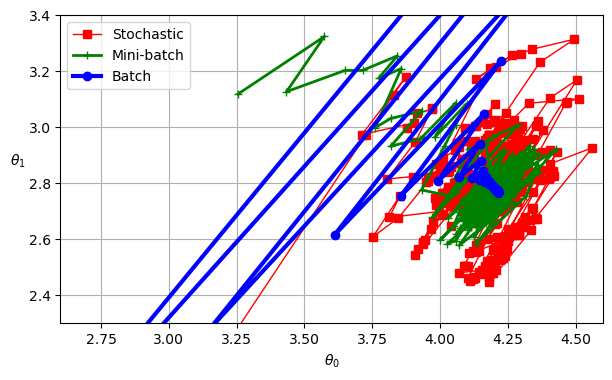

In [33]:
# extra code – this cell generates and saves Figure 4–11

from math import ceil

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

t0, t1 = 200, 1000  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

theta_path_mgd = []
for epoch in range(n_epochs):
    shuffled_indices = np.random.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for iteration in range(0, n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b_shuffled[idx : idx + minibatch_size]
        yi = y_shuffled[idx : idx + minibatch_size]
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(iteration)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

plt.figure(figsize=(7, 4))
plt.plot(theta_path_sgd[:, 0], theta_path_sgd[:, 1], "r-s", linewidth=1,
         label="Stochastic")
plt.plot(theta_path_mgd[:, 0], theta_path_mgd[:, 1], "g-+", linewidth=2,
         label="Mini-batch")
plt.plot(theta_path_bgd[:, 0], theta_path_bgd[:, 1], "b-o", linewidth=3,
         label="Batch")
plt.legend(loc="upper left")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$   ", rotation=0)
plt.axis([2.6, 4.6, 2.3, 3.4])
plt.grid()
#save_fig("gradient_descent_paths_plot")
plt.show()

## Mini-batch SGD using SGDRegressor and partial_fit (one step fitting)

Addd the history to track MSE.

In [34]:
import random
from sklearn.metrics import mean_squared_error

minisgd = SGDRegressor(eta0=0.01)

batch_size = 30
history=[]

for i in range(1000):
    mse=0
    idx = random.sample(range(X.shape[0]),batch_size)
    minisgd.partial_fit(X[idx], y.ravel()[idx])
    mse=mean_squared_error(minisgd.predict(X),y)
    history.append([i,mse])
    
minisgd.intercept_, minisgd.coef_

(array([4.23736153]), array([2.78598111]))

In [35]:
history=np.array(history)

Text(0, 0.5, 'Loss (MSE)')

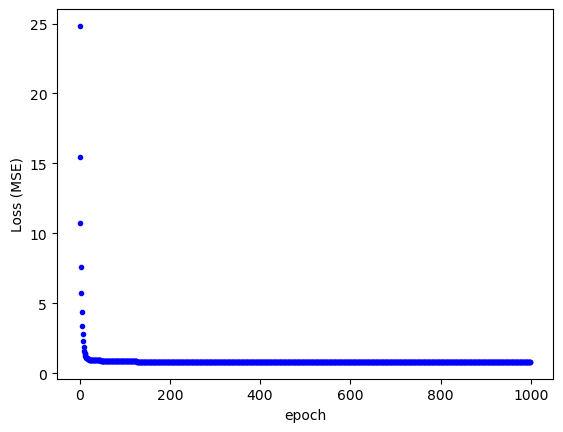

In [36]:
plt.plot(history[:,0], history[:,1], "b.")
plt.xlabel(r"epoch")
plt.ylabel(r"Loss (MSE)")

# Polynomial Regression

In [37]:
np.random.seed(42)
m2 = 100
X2 = 6 * np.random.rand(m2, 1) - 3
y2 = 0.5 * X2 ** 2 + X2 + 2 + np.random.randn(m2, 1)

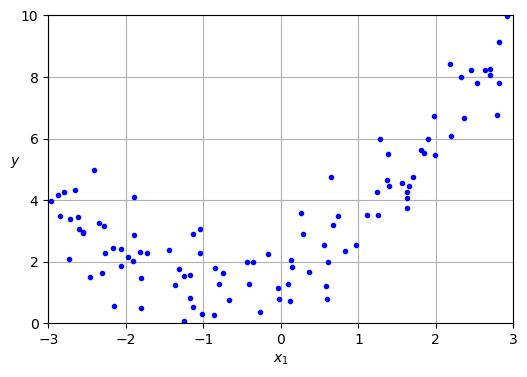

In [38]:
# extra code – this cell generates and saves Figure 4–12
plt.figure(figsize=(6, 4))
plt.plot(X2, y2, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
#save_fig("quadratic_data_plot")
plt.show()

In [39]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X2_poly = poly_features.fit_transform(X2)
X2[3]

array([0.59195091])

In [40]:
X2_poly[3]

array([0.59195091, 0.35040587])

In [41]:
lin_reg = LinearRegression()
lin_reg.fit(X2_poly, y2)
lin_reg.intercept_, lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

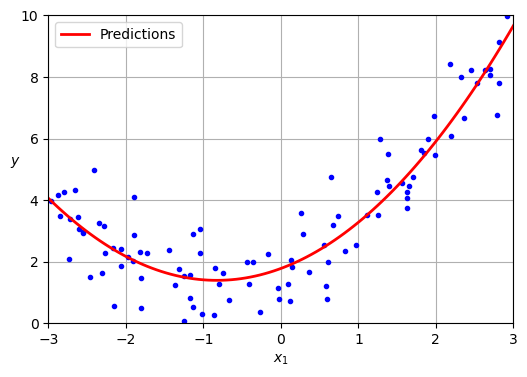

In [42]:
# extra code – this cell generates and saves Figure 4–13

X2_new = np.linspace(-3, 3, 100).reshape(100, 1)
X2_new_poly = poly_features.transform(X2_new)
y2_new = lin_reg.predict(X2_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(X2, y2, "b.")
plt.plot(X2_new, y2_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.axis([-3, 3, 0, 10])
plt.grid()
#save_fig("quadratic_predictions_plot")
plt.show()

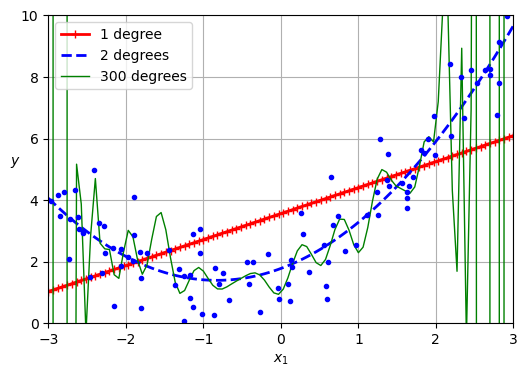

In [43]:
# extra code – this cell generates and saves Figure 4–14

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

plt.figure(figsize=(6, 4))

for style, width, degree in (("r-+", 2, 1), ("b--", 2, 2), ("g-", 1, 300)):
    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = make_pipeline(polybig_features, std_scaler, lin_reg)
    polynomial_regression.fit(X2, y2)
    y2_newbig = polynomial_regression.predict(X2_new)
    label = f"{degree} degree{'s' if degree > 1 else ''}"
    plt.plot(X2_new, y2_newbig, style, label=label, linewidth=width)

plt.plot(X2, y2, "b.", linewidth=3)
plt.legend(loc="upper left")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
#save_fig("high_degree_polynomials_plot")
plt.show()